# Phase 4: Feature Engineering (Lags and Rolling Statistics, No Leakage)

**Project:** FMCG Global Demand Planning Capstone
**Input:** `data/fmcg_clean.csv`, `data/abc_xyz_segments.csv`
**Output:** a model-ready feature table for Phase 5 (`data/fmcg_features.parquet`, or CSV if parquet is unavailable)

## Goal
Predict `units_sold` for a store-SKU on day *t* using only information that would really be available **before** day *t*. Models such as XGBoost and LightGBM cannot read a time series directly; they need each row to carry its own history as columns. That is what lag and rolling features do.

## The main risk: data leakage
**Leakage** means a feature accidentally contains information from the future (or from the target itself). The model then looks excellent in testing but fails in real use. In this notebook we guard against it by:
1. Building every history feature with `shift(1)` or more, so day *t* never sees its own value.
2. Computing everything **within each series** (store-SKU), so one series never leaks into another.
3. Excluding columns that are derived from the target (`net_sales`, `gross_sales`) or only known after the day ends (`stock_on_hand`, `stock_out_flag` for day *t*).
4. Running explicit tests that prove the lags and rolling windows are aligned correctly.

## 1. Load, sort and check the panel is complete

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 60)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
plt.rcParams["figure.figsize"] = (10, 4)

df = pd.read_csv("../data/fmcg_clean.csv", parse_dates=["date"])
df["series_id"] = df["store_id"] + "_" + df["sku_id"]

# Lags only make sense if rows are in time order WITHIN each series.
df = df.sort_values(["series_id", "date"]).reset_index(drop=True)
print("Rows:", f"{len(df):,}", "| Series:", df["series_id"].nunique())

Rows: 1,100,000 | Series: 1005


`shift(7)` means "7 rows back". That equals "7 days back" **only if every series has one row per day with no gaps**. We verify this before trusting any lag.

In [2]:
span = df.groupby("series_id")["date"].agg(n_rows="count", first="min", last="max")
span["expected_days"] = (span["last"] - span["first"]).dt.days + 1

print("Duplicate (series, date) rows:", df.duplicated(["series_id", "date"]).sum())
print("Series with missing days:", (span["n_rows"] != span["expected_days"]).sum())
print("Distinct start dates:", span["first"].nunique(), "| distinct end dates:", span["last"].nunique())

# Stop here if the panel has gaps: row-based shifts would then be wrong.
assert (span["n_rows"] == span["expected_days"]).all(), "Gaps found: reindex to daily before lagging"
print("Panel is complete: one row per day per series.")

Duplicate (series, date) rows: 0
Series with missing days: 0
Distinct start dates: 1 | distinct end dates: 2
Panel is complete: one row per day per series.


## 2. Lag features (what happened t-1, t-7, t-14, t-30 days ago)
- **lag_1:** yesterday's units (short-term momentum)
- **lag_7:** the same weekday last week (captures the weekly cycle found in Phase 2)
- **lag_14:** two weeks ago (extra weekly anchor, added beyond the roadmap)
- **lag_30:** about a month ago

`groupby("series_id").shift(k)` shifts *inside* each series, so the first *k* rows of every series become missing values (NaN) rather than borrowing from the previous series.

In [3]:
g = df.groupby("series_id")["units_sold"]
for k in [1, 7, 14, 30]:
    df[f"lag_{k}"] = g.shift(k)

df[["series_id", "date", "units_sold", "lag_1", "lag_7", "lag_14", "lag_30"]].iloc[:10]

,series_id,date,units_sold,lag_1,lag_7,lag_14,lag_30
0,STORE0001_SKU0001,2021-01-01,81,NaN,NaN,NaN,NaN
1,STORE0001_SKU0001,2021-01-02,134,81.000,NaN,NaN,NaN
2,STORE0001_SKU0001,2021-01-03,257,134.000,NaN,NaN,NaN
3,STORE0001_SKU0001,2021-01-04,284,257.000,NaN,NaN,NaN
4,STORE0001_SKU0001,2021-01-05,92,284.000,NaN,NaN,NaN
5,STORE0001_SKU0001,2021-01-06,53,92.000,NaN,NaN,NaN
6,STORE0001_SKU0001,2021-01-07,252,53.000,NaN,NaN,NaN
7,STORE0001_SKU0001,2021-01-08,97,252.000,81.000,NaN,NaN
8,STORE0001_SKU0001,2021-01-09,98,97.000,134.000,NaN,NaN
9,STORE0001_SKU0001,2021-01-10,29,98.000,257.000,NaN,NaN


## 3. Rolling statistics (recent average level and volatility)
Rolling features summarise a window of recent days: the mean (current level) and standard deviation (recent volatility).

**Leakage trap:** `rolling(7).mean()` on `units_sold` includes **today**. To avoid that we roll over `lag_1` (yesterday's value, already shifted), so the window covers days t-7 to t-1 and never touches day t.

In [4]:
by_series = df.groupby("series_id")["lag_1"]

for w in [7, 30]:
    # min_periods=w: only compute when a full window of history exists.
    df[f"roll_mean_{w}"] = by_series.rolling(w, min_periods=w).mean().reset_index(level=0, drop=True)
    df[f"roll_std_{w}"]  = by_series.rolling(w, min_periods=w).std().reset_index(level=0, drop=True)

df[["series_id", "date", "units_sold", "lag_1", "roll_mean_7", "roll_std_7", "roll_mean_30"]].iloc[30:36]

,series_id,date,units_sold,lag_1,roll_mean_7,roll_std_7,roll_mean_30
30,STORE0001_SKU0001,2021-01-31,171,130.000,136.000,42.446,135.433
31,STORE0001_SKU0001,2021-02-01,162,171.000,143.143,43.690,138.433
32,STORE0001_SKU0001,2021-02-02,80,162.000,133.429,24.508,139.367
33,STORE0001_SKU0001,2021-02-03,134,80.000,128.429,31.474,133.467
34,STORE0001_SKU0001,2021-02-04,75,134.000,128.429,31.474,128.467
35,STORE0001_SKU0001,2021-02-05,71,75.000,122.857,37.356,127.900


## 4. Recent promotion and stock-out history
Promotions can cause a dip afterwards (customers stocked up), and stock-outs distort recent sales (units are capped by missing stock). So we add what happened in the **past** only:
- `promo_last7`: promo days in the previous 7 days
- `stockout_lag1`: was there a stock-out yesterday?
- `stockout_last7`: stock-out days in the previous 7 days

In [5]:
df["promo_lag1"] = df.groupby("series_id")["promo_flag"].shift(1)
df["promo_last7"] = (df.groupby("series_id")["promo_lag1"]
                       .rolling(7, min_periods=7).sum()
                       .reset_index(level=0, drop=True))

df["stockout_lag1"] = df.groupby("series_id")["stock_out_flag"].shift(1)
df["stockout_last7"] = (df.groupby("series_id")["stockout_lag1"]
                          .rolling(7, min_periods=7).sum()
                          .reset_index(level=0, drop=True))

## 5. Static attributes and segments
Tree models need numbers, so we turn category-like columns into integer codes (label encoding). We also attach the ABC class and relative XYZ class from Phase 2.

We deliberately do **not** add per-series averages of the whole dataset (for example "mean units of this series"): they would be computed using future rows and leak information into the training period.

In [6]:
for col in ["country", "channel", "category", "subcategory", "brand", "store_id", "sku_id"]:
    df[f"{col}_code"] = df[col].astype("category").cat.codes

seg = pd.read_csv("../data/abc_xyz_segments.csv")[["series_id", "abc_class", "xyz_rel"]]
df = df.merge(seg, on="series_id", how="left")
df["abc_code"] = df["abc_class"].map({"A": 0, "B": 1, "C": 2})
df["xyz_rel_code"] = df["xyz_rel"].map({"X": 0, "Y": 1, "Z": 2})

print("Series without a segment:", df["abc_code"].isna().sum())

Series without a segment: 0


## 6. Which columns are allowed? (leakage audit)

**Excluded on purpose**

| Column | Why it is excluded |
|---|---|
| `net_sales`, `gross_sales` | Computed from `units_sold`, so they contain the answer |
| `margin_pct`, `purchase_cost` | Tied to the sold quantity or the supplier chosen that day (not known in advance) |
| `stock_on_hand`, `stock_out_flag` (day *t*) | Recorded at end of day, after sales happen; a stock-out is a consequence of sales |
| `lead_time_days`, `supplier_id` (day *t*) | Vary at random by row in this dataset and add no information (Phase 2) |

**Included because they are known before the day**
- Calendar: weekday, month, day, week of year, weekend and holiday flags
- Plans: `promo_flag`, `discount_pct`, `list_price` (promotions and prices are planned in advance)
- Weather: `temperature`, `rain_mm`. *Caveat:* real weather on day *t* is only known after the fact. In a live system you would use a weather **forecast**; here we treat it as available.
- Static attributes and segments

In [7]:
lag_feats    = ["lag_1", "lag_7", "lag_14", "lag_30"]
roll_feats   = ["roll_mean_7", "roll_std_7", "roll_mean_30", "roll_std_30"]
hist_feats   = ["promo_last7", "stockout_lag1", "stockout_last7"]
known_feats  = ["promo_flag", "discount_pct", "list_price", "is_holiday", "is_weekend",
                "weekday", "month", "day", "weekofyear", "temperature", "rain_mm"]
static_feats = ["country_code", "channel_code", "category_code", "subcategory_code",
                "brand_code", "store_id_code", "sku_id_code", "abc_code", "xyz_rel_code"]

feature_cols = lag_feats + roll_feats + hist_feats + known_feats + static_feats
target = "units_sold"
print(len(feature_cols), "features")

31 features


## 7. Leakage tests
We prove, on a real series, that each feature equals what it should be built from *earlier* rows only.
- `lag_1` at row *i* must equal `units_sold` at row *i-1*, and `lag_7` row *i-7*.
- `roll_mean_7` at row *i* must equal the average of `units_sold` for rows *i-7* to *i-1* (excluding row *i*).
- `roll_mean_30` likewise for rows *i-30* to *i-1*.
- The first row of every series must have no lag (no borrowing from the previous series).

In [8]:
rng = np.random.default_rng(42)
sid = rng.choice(df["series_id"].unique())
s = df[df["series_id"] == sid].reset_index(drop=True)
i = 100

assert s.loc[i, "lag_1"] == s.loc[i - 1, "units_sold"]
assert s.loc[i, "lag_7"] == s.loc[i - 7, "units_sold"]
assert s.loc[i, "lag_30"] == s.loc[i - 30, "units_sold"]
assert np.isclose(s.loc[i, "roll_mean_7"],  s.loc[i - 7:i - 1, "units_sold"].mean())
assert np.isclose(s.loc[i, "roll_mean_30"], s.loc[i - 30:i - 1, "units_sold"].mean())
assert df.groupby("series_id").head(1)["lag_1"].isna().all()
assert df.groupby("series_id").head(30)["lag_30"].isna().groupby(df["series_id"]).sum().eq(30).all()

print("All alignment tests passed for series", sid)

All alignment tests passed for series STORE0002_SKU0010


### 7.1 Red-flag check: correlation with the target
A feature that correlates almost perfectly with the target (above about 0.95) is suspicious. Strong lags are expected to correlate well (demand is persistent), but nothing should be near 1.

Rows before dropping warm-up days: 1,100,000 | after: 1,069,850
roll_mean_30    0.762
roll_mean_7     0.744
roll_std_30     0.706
roll_std_7      0.620
lag_7           0.617
lag_14          0.613
lag_1           0.611
lag_30          0.580
abc_code       -0.348
promo_flag      0.295
discount_pct    0.292
xyz_rel_code    0.171
sku_id_code    -0.122
is_weekend      0.111
weekday         0.088

Features with |corr| > 0.95: []


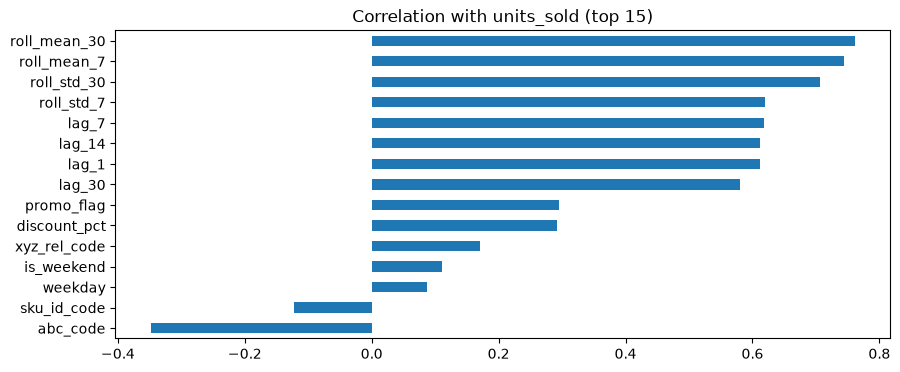

In [9]:
model_df = df.dropna(subset=lag_feats + roll_feats + hist_feats).copy()
print("Rows before dropping warm-up days:", f"{len(df):,}", "| after:", f"{len(model_df):,}")

corr = model_df[feature_cols + [target]].corr()[target].drop(target).sort_values(key=abs, ascending=False)
print(corr.head(15).round(3).to_string())
print("\nFeatures with |corr| > 0.95:", list(corr[corr.abs() > 0.95].index))

corr.head(15).sort_values().plot(kind="barh", title="Correlation with units_sold (top 15)")
plt.show()

## 8. Time-based split plan
Never split time series randomly: shuffling would put future days in training and past days in testing. We always train on the past and test on the future.

- **Train:** up to 2022-12-31
- **Validation:** 2023-01-01 to 2023-06-30
- **Test:** 2023-07-01 onward (covers the Beverages summer peak and the Snacks Nov-Dec peak)

Phase 5 will also use **expanding-window cross-validation** (several train/validate folds moving forward in time) for tuning.

In [10]:
train = model_df[model_df["date"] <= "2022-12-31"]
valid = model_df[(model_df["date"] >= "2023-01-01") & (model_df["date"] <= "2023-06-30")]
test  = model_df[model_df["date"] >= "2023-07-01"]

for name, part in [("train", train), ("validation", valid), ("test", test)]:
    print(f"{name:11s} {part['date'].min().date()} to {part['date'].max().date()}  rows: {len(part):,}")

train       2021-01-31 to 2022-12-31  rows: 703,390
validation  2023-01-01 to 2023-06-30  rows: 181,724
test        2023-07-01 to 2023-12-31  rows: 184,736


## 9. Naive baselines (the score Phase 5 must beat)
Before building XGBoost or LightGBM we need a yardstick. Simple rules that use the new features:
- **lag_1:** predict yesterday's units
- **lag_7:** predict the same weekday last week (seasonal naive)
- **roll_mean_7 / roll_mean_30:** predict the recent average

**WAPE** (weighted absolute percentage error) = total absolute error / total actual units. It is robust to zero-sales days and easy to read: 0.15 means errors total 15% of demand. A model is only useful if it clearly beats these.

In [11]:
def wape(y, yhat):
    return np.abs(y - yhat).sum() / y.sum()

rows = []
for name in ["lag_1", "lag_7", "roll_mean_7", "roll_mean_30"]:
    for label, part in [("validation", valid), ("test", test)]:
        rows.append({"baseline": name, "set": label,
                     "WAPE": wape(part[target], part[name]),
                     "MAE": np.abs(part[target] - part[name]).mean()})

baselines = pd.DataFrame(rows).pivot(index="baseline", columns="set", values=["WAPE", "MAE"])
print(baselines.round(3))

              WAPE               MAE           
set           test validation   test validation
baseline                                       
lag_1        0.435      0.434 26.340     25.092
lag_7        0.429      0.427 25.982     24.703
roll_mean_30 0.316      0.313 19.120     18.107
roll_mean_7  0.330      0.328 19.967     18.971


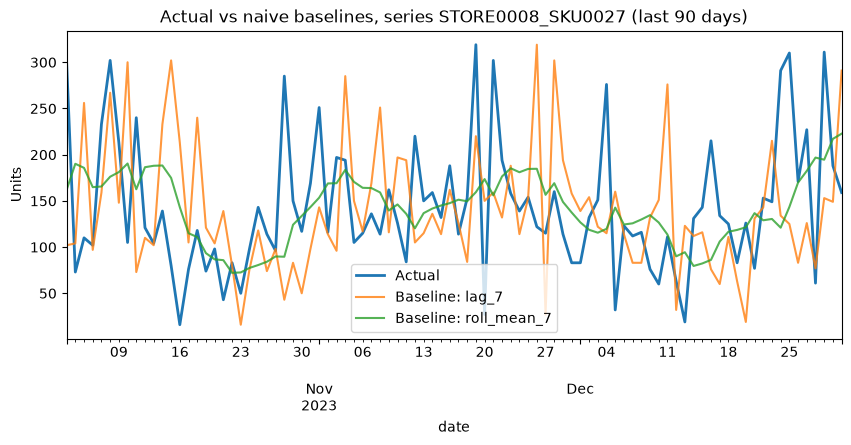

In [12]:
# Visual check on the highest-revenue series: actual vs two baselines, last 90 days.
top = pd.read_csv("../data/abc_xyz_segments.csv").sort_values("net_sales", ascending=False)["series_id"].iloc[0]
v = model_df[model_df["series_id"] == top].tail(90).set_index("date")

v[target].plot(label="Actual", linewidth=2)
v["lag_7"].plot(label="Baseline: lag_7", alpha=0.8)
v["roll_mean_7"].plot(label="Baseline: roll_mean_7", alpha=0.8)
plt.title(f"Actual vs naive baselines, series {top} (last 90 days)")
plt.ylabel("Units")
plt.legend()
plt.show()

## 10. Save the feature table for Phase 5

In [13]:
keep = ["series_id", "date", target] + feature_cols
out = model_df[keep].copy()

# Smaller numbers save memory and disk; trees do not need float64.
for c in out.select_dtypes("float64").columns:
    out[c] = out[c].astype("float32")

try:
    out.to_parquet("../data/fmcg_features.parquet", index=False)
    print("Saved parquet:", out.shape)
except Exception as e:
    print("Parquet not available (", type(e).__name__, "), saving CSV instead")
    out.to_csv("../data/fmcg_features.csv", index=False)
    print("Saved CSV:", out.shape)

Parquet not available ( ImportError ), saving CSV instead
Saved CSV: (1069850, 34)


## 11. Summary of findings
*(Fill in after running. Suggested prompts:)*

- **Panel check:** Was every series complete (one row per day, no gaps)? How many warm-up rows were dropped?
- **Features built:** lags (1, 7, 14, 30), rolling mean and std (7, 30), recent promo and stock-out history, calendar, plans, weather, static attributes.
- **Leakage controls:** shift(1) before rolling, per-series grouping, excluded columns and why, tests that passed.
- **Correlations:** Which features track the target most? Any above 0.95?
- **Split plan:** train, validation and test periods and row counts.
- **Baselines:** WAPE of lag_1, lag_7, roll_mean_7 and roll_mean_30 on validation and test. Which naive rule is best, and what does Phase 5 need to beat?
- **Limitations:** weather is treated as known in advance; lags inherit stock-out distortion (about 3% of days); promotions and prices are assumed to be planned ahead.